# Interpolation with `scipy.interpolate` (2-D)

Given data $(x_i, y_i, z_i)$, build a function $p(x, y)$ with $p(x_i, y_i) = z_i$ and evaluate it **between** the data points.
As in 1-D, every method is used the same way: **build once**, then **evaluate** at as many new points as you like.

In 2-D there are two very different situations:

**A. Data on a grid**: a value $z_{ij}$ at every pair $(x_i, y_j)$, e.g. a table, an image, a simulation output.

| method | call | continuous | local? | overshoot? |
|---|---|---|---|---|
| nearest | `si.RegularGridInterpolator((x, y), Z, method="nearest")` | no | yes | never |
| linear (bilinear) | `si.RegularGridInterpolator((x, y), Z)` | $p$ | yes | never |
| cubic | `si.RegularGridInterpolator((x, y), Z, method="cubic")` | $p$ and its derivatives | no | can overshoot |
| PCHIP | `si.RegularGridInterpolator((x, y), Z, method="pchip")` | $p$ and first derivatives | yes | never |

**B. Scattered data**: values at points $(x_k, y_k)$ with no pattern, e.g. weather stations, GPS measurements.

| method | call | continuous | local? | overshoot? |
|---|---|---|---|---|
| nearest | `si.griddata(pts, z, (X, Y), method="nearest")` | no | yes | never |
| linear (on triangles) | `si.griddata(pts, z, (X, Y), method="linear")` | $p$ | yes | never |
| cubic (Clough–Tocher) | `si.griddata(pts, z, (X, Y), method="cubic")` | $p$ and first derivatives | yes | can overshoot |
| radial basis functions | `si.RBFInterpolator(pts, z)` | smooth | no | can overshoot |

More details: SciPy User Guide, *Interpolation → Multivariate data interpolation on a regular grid* and *Scattered data interpolation*:
<https://docs.scipy.org/doc/scipy/tutorial/interpolate/ND_regular_grid.html>
<https://docs.scipy.org/doc/scipy/tutorial/interpolate/ND_unstructured.html>

- **On a grid**, the methods are the 1-D methods from last class applied **along $x$, then along $y$** (tensor products). They behave just like their 1-D versions.
- **Linear, nearest, PCHIP**: local and safe. **Cubic**: smoothest, but can overshoot.
- **Scattered data**: `griddata` splits the plane into **triangles** between the data points and interpolates on each triangle. It returns `nan` **outside** the region covered by the triangles (the *convex hull* of the points).
- **RBF** builds one smooth function from all points at once. It is defined everywhere, also outside the data, so it will happily **extrapolate**.
- The grid vectors `x` and `y` must be **increasing**. `Z` has shape `(len(x), len(y))`, with `Z[i, j]` the value at `(x[i], y[j])`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as si

## Grids in NumPy: `meshgrid`

`np.meshgrid(x, y, indexing="ij")` turns two 1-D vectors into two 2-D arrays `X, Y` with `X[i, j] = x[i]` and `Y[i, j] = y[j]`.
Then any formula in `X` and `Y` gives a table of values on the grid. Always use `indexing="ij"`, so that `Z[i, j]` belongs to `(x[i], y[j])`, which is what `RegularGridInterpolator` expects.

In [2]:
x = np.array([0, 1, 2.])
y = np.array([10, 20, 30, 40.])
X, Y = np.meshgrid(x, y, indexing="ij")
print("X =\n", X)
print("Y =\n", Y)
print(f"shape:{X.shape}= (len(x), len(y))")

X =
 [[0. 0. 0. 0.]
 [1. 1. 1. 1.]
 [2. 2. 2. 2.]]
Y =
 [[10. 20. 30. 40.]
 [10. 20. 30. 40.]
 [10. 20. 30. 40.]]
shape:(3, 4)= (len(x), len(y))


## Example 1: the running example, in two directions

We take the seven heights from last class, $h = (0, 0.1, 0.3, 1.8, 2.0, 2.0, 2.1)$, and put them along both axes: $z_{ij} = h_i + h_j$.
The surface rises in both directions and levels off. We build the four grid interpolants and evaluate them on a fine $121 \times 121$ mesh.

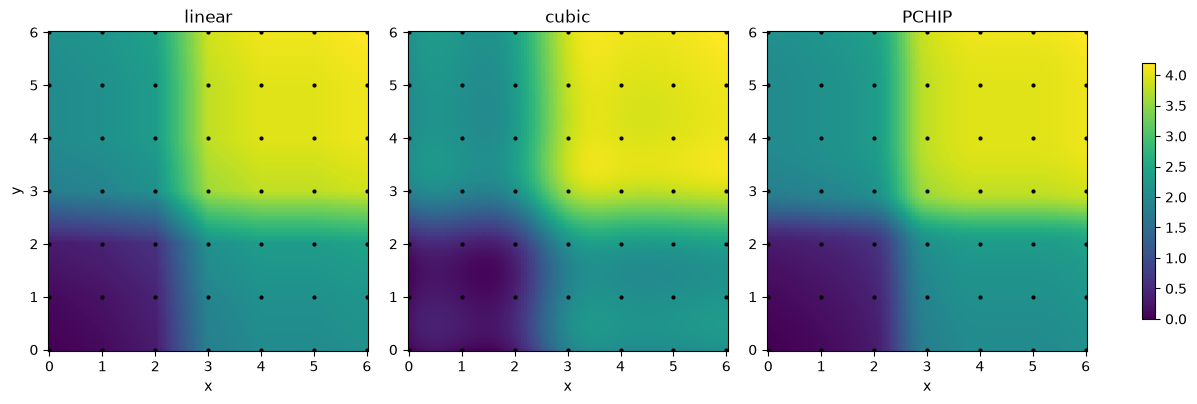

In [3]:
x = np.array([0, 1, 2, 3, 4, 5, 6.])
y = np.array([0, 1, 2, 3, 4, 5, 6.])
h = np.array([0, 0.1, 0.3, 1.8, 2.0, 2.0, 2.1])
Z = h[:, None] + h[None, :]          # Z[i, j] = h[i] + h[j], shape (7, 7)

names = ["linear", "cubic", "PCHIP"]
methods = [si.RegularGridInterpolator((x, y), Z, method=m)
           for m in ["linear", "cubic", "pchip"]]

xnew = np.linspace(0, 6, 121)
Xn, Yn = np.meshgrid(xnew, xnew, indexing="ij")
Xd, Yd = np.meshgrid(x, y, indexing="ij")    # data locations, for plotting

fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
for ax, name, p in zip(axs, names, methods):
    im = ax.pcolormesh(Xn, Yn, p((Xn, Yn)), shading="auto", vmin=0, vmax=4.2)
    ax.plot(Xd, Yd, "k.", ms=4)
    ax.set_title(name); ax.set_aspect("equal"); ax.set_xlabel("x")
axs[0].set_ylabel("y")
fig.colorbar(im, ax=axs, shrink=0.8)
plt.show()

On a picture of the whole surface the smooth methods look almost the same. A **slice** at a fixed $y$ shows the differences more clearly: it is a 1-D curve, like last class.
We cut at $y = 4.5$, between two grid lines.

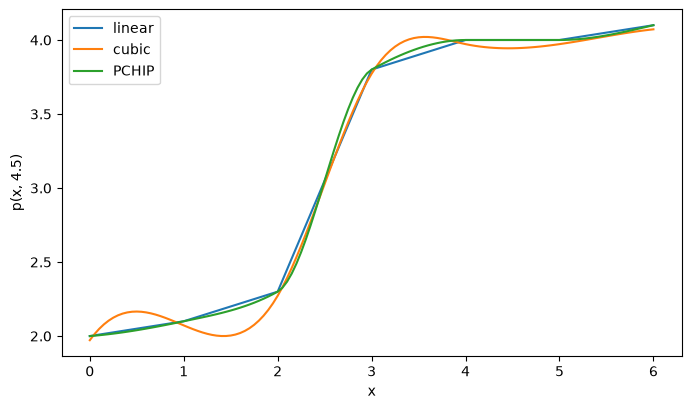

In [4]:
ycut = 4.5
pts_cut = np.column_stack([xnew, np.full_like(xnew, ycut)])   # points (x, 4.5), shape (121, 2)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, p in zip(names, methods):
    ax.plot(xnew, p(pts_cut), label=name)
ax.set_xlabel("x"); ax.set_ylabel(f"p(x, {ycut})")
ax.legend()
plt.show()

As in 1-D we check two things on the fine mesh:

- **range**: do the values stay inside $[\min z, \max z] = [0, 4.2]$?
- **monotone**: the data never decrease in $x$ or in $y$, so does the surface also never decrease in both directions?

In [5]:
print(f"{'method':9s} {'min':>8s} {'max':>8s}  never decreases?")
for name, p in zip(names, methods):
    V = p((Xn, Yn))
    increasing = (np.all(np.diff(V, axis=0) >= -1e-12)       # along x
                  and np.all(np.diff(V, axis=1) >= -1e-12))  # along y
    print(f"{name:9s} {V.min():8.4f} {V.max():8.4f}  {increasing}")

method         min      max  never decreases?
linear      0.0000   4.2000  True
cubic       0.0000   4.2000  False
PCHIP       0.0000   4.2000  True


- Linear and PCHIP keep the shape of the data: they stay in range and never decrease.
- Cubic is the smoothest, but it **goes down** in places although the data only go up, exactly like the cubic spline in 1-D.

## Example 2: a cliff

Now the data jump from 0 to 1 across the diagonal $x + y = 7$, like the edge of a plateau.
Smooth methods have to bend through this jump, and that is where overshoot appears.

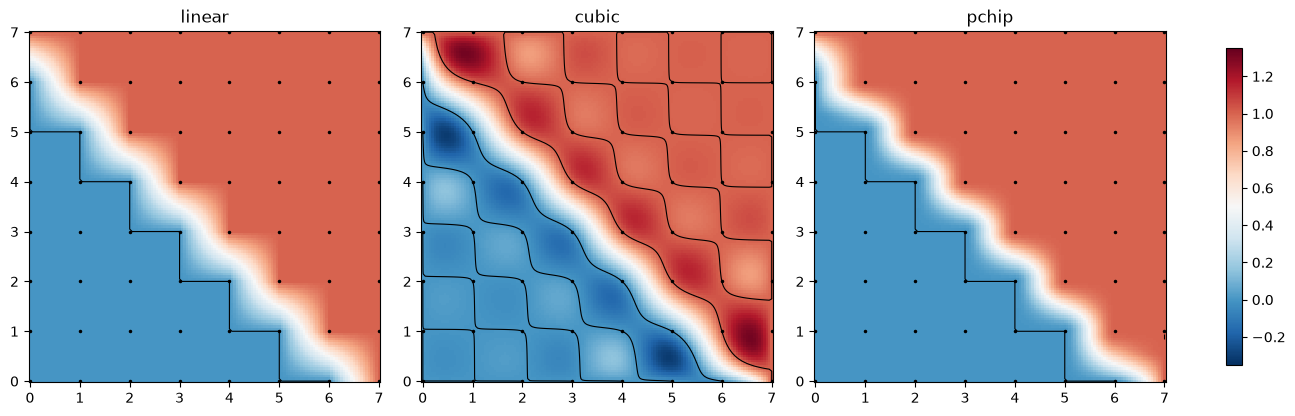

linear  min = 0.0000   max = 1.0000
cubic   min = -0.3125   max = 1.3220
pchip   min = 0.0000   max = 1.0000


In [6]:
x2 = np.arange(8.)
y2 = np.arange(8.)
X2, Y2 = np.meshgrid(x2, y2, indexing="ij")
Z2 = np.where(X2 + Y2 >= 7, 1.0, 0.0)    # 0 below the diagonal, 1 above

xnew2 = np.linspace(0, 7, 141)
Xn2, Yn2 = np.meshgrid(xnew2, xnew2, indexing="ij")

fig, axs = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, m in zip(axs, ["linear", "cubic", "pchip"]):
    V = si.RegularGridInterpolator((x2, y2), Z2, method=m)((Xn2, Yn2))
    im = ax.pcolormesh(Xn2, Yn2, V, shading="auto", cmap="RdBu_r", vmin=-0.35, vmax=1.35)
    ax.contour(Xn2, Yn2, V, levels=[0, 1], colors="k", linewidths=0.8)
    ax.plot(X2, Y2, "k.", ms=3)
    ax.set_title(m); ax.set_aspect("equal")
fig.colorbar(im, ax=axs, shrink=0.9)
plt.show()

for m in ["linear", "cubic", "pchip"]:
    V = si.RegularGridInterpolator((x2, y2), Z2, method=m)((Xn2, Yn2))
    print(f"{m:7s} min = {V.min():.4f}   max = {V.max():.4f}")

- The black lines are the levels 0 and 1. Linear and PCHIP stay in $[0, 1]$: away from the cliff they are exactly 0 or 1.
- Cubic dips well **below 0** on the low side and rises well **above 1** on the high side, by about 30 %. The ripples spread away from the cliff because the cubic is not local.
- **For data with jumps or flat parts, prefer `"pchip"` (or `"linear"`).**

A **slice** at $x=y$ shows the differences more clearly.

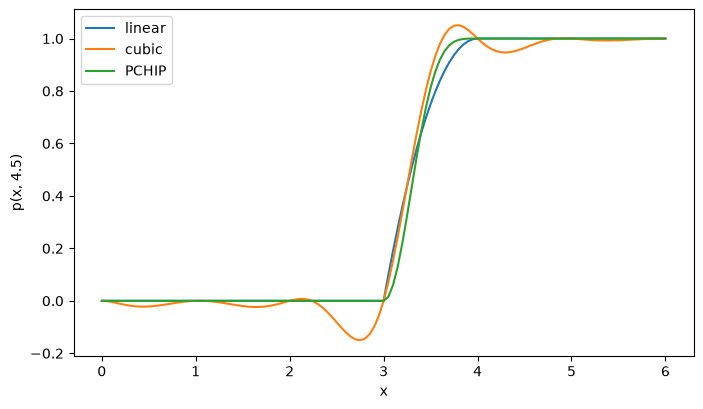

In [7]:
# diagonal cut
pts_cut = np.column_stack([xnew,xnew])


fig, ax = plt.subplots(figsize=(8, 4.5))
for name, m in zip(names, ["linear", "cubic", "pchip"]):
    p = si.RegularGridInterpolator((x2, y2), Z2, method=m)
    ax.plot(xnew, p(pts_cut), label=name)
ax.set_xlabel("x"); ax.set_ylabel(f"p(x, {ycut})")
ax.legend()
plt.show()

## Example 3: accuracy on a smooth function

Sample $f(x, y) = \sin x \cos y$ on an $n \times n$ grid over $[0, 2\pi]^2$ and compute the maximum error $\max |p - f|$ on a fine $201 \times 201$ mesh.

In [8]:
def f(x, y):
    return np.sin(x) * np.cos(y)

xf = np.linspace(0, 2*np.pi, 201)
Xf, Yf = np.meshgrid(xf, xf, indexing="ij")

print(f"{'n':>4s}" + "".join(f"{name:>12s}" for name in names))
for n in [6, 11, 21, 41]:
    xs = np.linspace(0, 2*np.pi, n)
    Xs, Ys = np.meshgrid(xs, xs, indexing="ij")
    Zs = f(Xs, Ys)
    errs = []
    for m in ["linear", "cubic", "pchip"]:
        p = si.RegularGridInterpolator((xs, xs), Zs, method=m)
        errs.append(np.max(np.abs(p((Xf, Yf)) - f(Xf, Yf))))
    print(f"{n:4d}" + "".join(f"{e:12.2e}" for e in errs))

   n      linear       cubic       PCHIP
   6    3.31e-01    7.15e-02    2.74e-01
  11    9.10e-02    3.50e-03    6.23e-02
  21    2.39e-02    2.60e-04    7.17e-03
  41    5.88e-03    3.59e-05    1.78e-03


- **Cubic is the most accurate**, and its error falls fastest as $n$ grows.
- Linear: doubling the points per direction cuts the error by about 4 ($O(h^2)$). 
- Note the cost: an $n \times n$ grid has $n^2$ points. Going from $n = 21$ to $n = 41$ means about **4 times** as much data. In 2-D, a more accurate method saves a lot more than in 1-D.

## Example 4: scattered data

Now the data are at 100 **random** points in $[0, 2\pi]^2$, again from $f(x, y) = \sin x \cos y$.
There is no grid, so `RegularGridInterpolator` cannot be used. We use `griddata` and `RBFInterpolator`.

- `si.griddata(pts, z, (Xn, Yn), method=...)` builds **and** evaluates in one call. `pts` has shape `(N, 2)`, one row $(x_k, y_k)$ per point.
- `si.RBFInterpolator(pts, z)` builds; it is evaluated at points of shape `(M, 2)`. To evaluate on a mesh, flatten the mesh into points and reshape the result back.

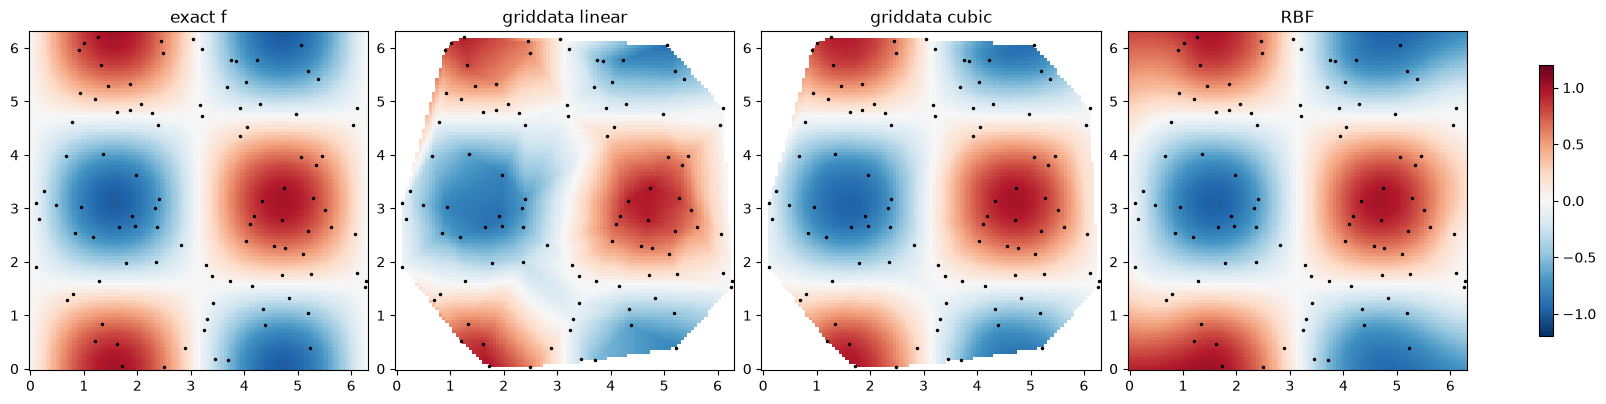

In [9]:
rng = np.random.default_rng(1)          # fixed seed: same "random" points every run
pts = rng.uniform(0, 2*np.pi, size=(100, 2))
z = f(pts[:, 0], pts[:, 1])

xnew4 = np.linspace(0, 2*np.pi, 101)
Xn4, Yn4 = np.meshgrid(xnew4, xnew4, indexing="ij")

V_lin = si.griddata(pts, z, (Xn4, Yn4), method="linear")
V_cub = si.griddata(pts, z, (Xn4, Yn4), method="cubic")
rbf = si.RBFInterpolator(pts, z)
V_rbf = rbf(np.column_stack([Xn4.ravel(), Yn4.ravel()])).reshape(Xn4.shape)


fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
panels = [("exact f", f(Xn4, Yn4)), ("griddata linear", V_lin),
          ("griddata cubic", V_cub), ("RBF", V_rbf)]
for ax, (title, V) in zip(axs, panels):
    im = ax.pcolormesh(Xn4, Yn4, V, shading="auto", cmap="RdBu_r", vmin=-1.2, vmax=1.2)
    ax.plot(pts[:, 0], pts[:, 1], "k.", ms=3)
    ax.set_title(title); ax.set_aspect("equal")
fig.colorbar(im, ax=axs, shrink=0.8)
plt.show()

The white areas in the `griddata` pictures are `nan`: those points lie **outside** the triangles, so `griddata` refuses to answer. RBF fills the whole square.

To compare the methods fairly we measure the error only where `griddata` gives a value. With scattered points the maximum error is dominated by a few long, thin triangles near the edge, so we also print the **root-mean-square (RMS) error**, a typical error over the mesh.

In [10]:
F = f(Xn4, Yn4)
inside = ~np.isnan(V_lin)                     # True where griddata has a value
print(f"points outside the triangles: {100 * (~inside).mean():.1f} %\n")

print(f"{'method':16s} {'max err':>9s} {'RMS err':>9s}   (inside only)")
for name, V in [("griddata linear", V_lin), ("griddata cubic", V_cub), ("RBF", V_rbf)]:
    e = np.abs(V - F)[inside]
    print(f"{name:16s} {e.max():9.3f} {np.sqrt(np.mean(e**2)):9.3f}")

e_out = np.abs(V_rbf - F)[~inside]
print(f"\nRBF outside the triangles: max err = {e_out.max():.3f}")

points outside the triangles: 19.6 %

method             max err   RMS err   (inside only)
griddata linear      0.414     0.078
griddata cubic       0.146     0.017
RBF                  0.168     0.018

RBF outside the triangles: max err = 0.930


- `griddata` gives **no answer** near the corners and edges of the square. Use `fill_value=...` to choose what is returned there instead of `nan`.
- Cubic and RBF are about equally accurate inside, and both are much better than linear (RMS error about 4 times smaller).
- RBF **does** answer outside the data, but there it is extrapolating. Its error is larger there: be careful trusting values far from any data point.

## Exercises

**Syntax for each method**

Data on a grid, `Z` of shape `(len(x), len(y))`:

| method | build | evaluate on a mesh |
|---|---|---|
| linear | `p = si.RegularGridInterpolator((x, y), Z)` | `p((Xn, Yn))` |
| cubic | `p = si.RegularGridInterpolator((x, y), Z, method="cubic")` | `p((Xn, Yn))` |
| PCHIP | `p = si.RegularGridInterpolator((x, y), Z, method="pchip")` | `p((Xn, Yn))` |

Scattered data, `pts` of shape `(N, 2)` and `z` of shape `(N,)`:

| method | build | evaluate on a mesh |
|---|---|---|
| linear | (none) | `si.griddata(pts, z, (Xn, Yn), method="linear")` |
| cubic | (none) | `si.griddata(pts, z, (Xn, Yn), method="cubic")` |
| RBF | `r = si.RBFInterpolator(pts, z)` | `r(np.column_stack([Xn.ravel(), Yn.ravel()])).reshape(Xn.shape)` |

<br><br>

| useful extra | call |
|---|---|
| $n$ equally spaced points on $[a, b]$ | `np.linspace(a, b, n)` |
| a mesh from two vectors | `X, Y = np.meshgrid(x, y, indexing="ij")` |
| sample a function on the mesh | `Z = f(X, Y)` |
| $N$ random points in $[a, b]^2$ | `rng = np.random.default_rng(0); pts = rng.uniform(a, b, size=(N, 2))` |
| sample a function at those points | `z = f(pts[:, 0], pts[:, 1])` |
| evaluate at a few single points | `p([[x1, y1], [x2, y2]])`, `si.griddata(pts, z, [[x1, y1], [x2, y2]])`, `r([[x1, y1], [x2, y2]])` |
| value instead of `nan` outside the data | `si.griddata(..., fill_value=v)` |

<br><br>

| checking a surface `V` | call |
|---|---|
| smallest and largest value (ignoring `nan`) | `np.nanmin(V)`, `np.nanmax(V)` |
| maximum error against a known $f$ | `np.max(np.abs(V - f(Xn, Yn)))` (use `np.nanmax` if `V` has `nan`) |
| where is there a value? | `inside = ~np.isnan(V)` |
| number of `nan` values | `np.isnan(V).sum()` |

<br><br>

| plotting | call |
|---|---|
| a row of `k` plots | `fig, axs = plt.subplots(1, k, figsize=(4*k, 4), constrained_layout=True)` |
| colour plot of a surface | `im = ax.pcolormesh(Xn, Yn, V, shading="auto")` |
| same colour scale on all plots | `ax.pcolormesh(..., vmin=a, vmax=b)` |
| colour bar | `fig.colorbar(im, ax=axs)` |
| contour lines | `ax.contour(Xn, Yn, V, levels=10, colors="k")` |
| plot the data points | `ax.plot(pts[:, 0], pts[:, 1], "k.")` |
| equal scale on both axes | `ax.set_aspect("equal")` |
| a slice at fixed $y = c$ (1-D curve) | `p(np.column_stack([xnew, np.full_like(xnew, c)]))` |


**Exercise 1.** The Franke function on $[0, 1]^2$, a standard test surface with two peaks and a dip:

```python
def franke(x, y):
    return (0.75 * np.exp(-((9*x - 2)**2 + (9*y - 2)**2) / 4)
          + 0.75 * np.exp(-(9*x + 1)**2 / 49 - (9*y + 1) / 10)
          + 0.50 * np.exp(-((9*x - 7)**2 + (9*y - 3)**2) / 4)
          - 0.20 * np.exp(-(9*x - 4)**2 - (9*y - 7)**2))
```

(a) Sample it on a $10 \times 10$ grid (`np.linspace(0, 1, 10)` in each direction). Interpolate with the three grid methods.
Evaluate on a **finer mesh** of $101 \times 101$ points and plot the three results next to the exact function, with the same colour scale.

(b) Print the maximum error for each method. Repeat with $n = 5, 10, 20, 40$ points per direction and make an error table as in Example 3. Which method wins? By what factor does the linear error drop when $n$ doubles?


In [11]:
# Exercise 1



**Exercise 2.** Twelve weather stations in a $100 \times 100$ km region measure the temperature (°C). Station 12 is on a mountain top.

```python
sx = np.array([10, 30, 55, 80, 15, 40, 65, 85, 20, 50, 75, 45.])     # km east
sy = np.array([15, 10, 20, 15, 45, 40, 50, 45, 80, 75, 85, 60.])     # km north
T  = np.array([14.2, 15.1, 13.8, 12.9, 11.5, 9.8, 6.2, 11.8, 10.4, 8.9, 10.1, 3.5])
pts = np.column_stack([sx, sy])
```

(a) Make a temperature map on a mesh of $201 \times 201$ points over $[0, 100]^2$ with `griddata` (linear and cubic) and with `RBFInterpolator`. Plot the three maps with the stations marked.

(b) Print the smallest and largest temperature of each map (`np.nanmin`, `np.nanmax`). The measurements are between 3.5 and 15.1 °C. Which methods go outside this range?


In [12]:
# Exercise 2
sx = np.array([10, 30, 55, 80, 15, 40, 65, 85, 20, 50, 75, 45.])     # km east
sy = np.array([15, 10, 20, 15, 45, 40, 50, 45, 80, 75, 85, 60.])     # km north
T  = np.array([14.2, 15.1, 13.8, 12.9, 11.5, 9.8, 6.2, 11.8, 10.4, 8.9, 10.1, 3.5])
pts = np.column_stack([sx, sy])


